Setup: loads data and runs the bootstrap (10,000 replicates, seed 42)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df2 = pd.read_csv('./data/diabetes.csv')
df2['outcome'] = (df2['outcome'] == 'success').astype(int)

In [4]:
np.random.seed(42)
R = 10_000

df_met = df2.loc[ df2['treatment'] == 'met',:]
df_rosi = df2.loc[ df2['treatment'] == 'rosi',:]
df_life = df2.loc[ df2['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_life = []

ate_met_rosi = []
ate_met_life = []
ate_rosi_life = []

for t in range(R):
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_life_t = df_life.sample(frac=1.0, replace=True)

    o_met = df_met_t['outcome'].mean()
    o_rosi = df_rosi_t['outcome'].mean()
    o_life = df_life_t['outcome'].mean()

    outcome_met.append(o_met)
    outcome_rosi.append(o_rosi)
    outcome_life.append(o_life)

    ate_met_rosi.append(o_met - o_rosi)
    ate_met_life.append(o_met - o_life)
    ate_rosi_life.append(o_rosi - o_life)

In [5]:
print(df2.groupby('treatment')['outcome'].mean().round(3), '\n')

print('met - rosi')
print('90% CI:', np.quantile(ate_met_rosi, [.05, .95]).round(3))
print('95% CI:', np.quantile(ate_met_rosi, [.025, .975]).round(3))
print('99% CI:', np.quantile(ate_met_rosi, [.005, .995]).round(3), '\n')

print('met - lifestyle')
print('90% CI:', np.quantile(ate_met_life, [.05, .95]).round(3))
print('95% CI:', np.quantile(ate_met_life, [.025, .975]).round(3))
print('99% CI:', np.quantile(ate_met_life, [.005, .995]).round(3), '\n')

print('rosi - lifestyle')
print('90% CI:', np.quantile(ate_rosi_life, [.05, .95]).round(3))
print('95% CI:', np.quantile(ate_rosi_life, [.025, .975]).round(3))
print('99% CI:', np.quantile(ate_rosi_life, [.005, .995]).round(3))

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: outcome, dtype: float64 

met - rosi
90% CI: [-0.208 -0.054]
95% CI: [-0.221 -0.041]
99% CI: [-0.247 -0.011] 

met - lifestyle
90% CI: [-0.129  0.026]
95% CI: [-0.142  0.039]
99% CI: [-0.171  0.069] 

rosi - lifestyle
90% CI: [0.003 0.153]
95% CI: [-0.01   0.169]
99% CI: [-0.04   0.195]


# Lab 6 Report: Review of a Three Armed Pre-Diabetes Trial

**Background:** This report reviews a randomized controlled trial comparing three interventions for pre-diabetic patients intended to prevent progression to type 2 diabetes. These are: Metformin, Rosiglitazone, and lifestyle adjustment (ex: diet and exercise). A total of 699 participants were randomized into three arms of almost equal size, and each participant's outcome was recorded as a success or a failure. For analysis, success was coded as 1 and failure as 0, so each arm's average outcome is its success rate. The goal of this review is to determine whether the trial provides evidence that any intervention one outperforms the others to a significant and statistically credible degree.

**Method:** Treatment effects were estimated as differences in success rates between pairs of arms (the average treatment effect, ATE). To quantify uncertainty, each arm was resampled separately and independantly with replacement 10,000 times. This preserves each arm's original size, which is appropriate for a randomized design. For each replicate, the three success rates and the three pairwise differences were recorded. The confidence intervals were constructed using the percentile method where the 95% interval is bounded by the 2.5th and 97.5th percentiles of the bootstrap distribution. A difference is considered statistically significant when its interval excludes zero.

**Visualization: Table 1. Outcomes by treatment arm:**

| Treatment | N | Successes (0) | Failures (1) | Success rate |
|---|---|---|---|---|
| Lifestyle | 234 | 125 | 109 | 53.4% |
| Metformin | 232 | 112 | 120 | 48.3% |
| Rosiglitazone | 233 | 143 | 90 | 61.4% |

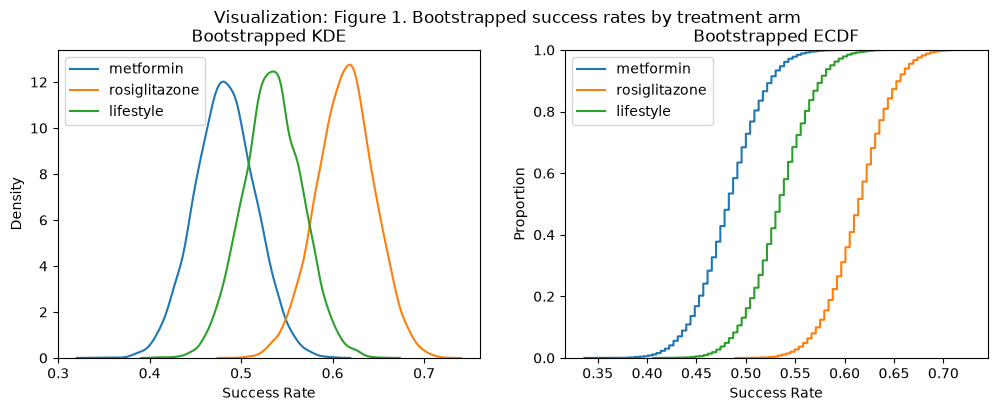

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='lifestyle', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='lifestyle', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

ax[0].legend()
ax[1].legend()
fig.suptitle('Visualization: Figure 1. Bootstrapped success rates by treatment arm:')
plt.show()

**Results.** Rosiglitazone produced the highest success rate (61.4%), followed by lifestyle adjustment (53.4%) and Metformin (48.3%). Figure 1 shows the bootstrapped sampling distributions of each arm's success rate: the Metformin and Rosiglitazone distributions are almost separate, and lifestyle overlaps with both. Table 2 and Figure 2 (below) report the pairwise treatment effects. The only comparison between two interventions that is statistically significant at all levels of the confidence interval is Metformin versus Rosiglitazone. Metformin's success rate is an estimated 13.1 percentage points lower, with a 95% confidence interval of -22.1 to -4.1 points that excludes zero even at the 99% level. The comparison of Metformin and lifestyle adjustment is not significant at any level (95% CI: -14.2 to 3.9 points). Rosiglitazone outperformed lifestyle adjustment by an estimated 8 points, but this difference is only marginal. It is significant at the 90% level and not at the 95% level (95% CI: -1.0 to 16.9 points).

**Visualization: Table 2. Pairwise average treatment effects (difference in success rate):**

| Comparison | ATE | 90% CI | 95% CI | 99% CI | Significant at 95%? |
|---|---|---|---|---|---|
| Metformin − Rosiglitazone | -0.131 | [−0.208, −0.054] | [−0.221, −0.041] | [−0.247, −0.011] | Yes |
| Metformin − Lifestyle | −0.051 | [−0.129, 0.026] | [−0.142, 0.039] | [−0.171, 0.069] | No |
| Rosiglitazone − Lifestyle | +0.080 | [0.003, 0.153] | [−0.010, 0.169] | [−0.040, 0.195] | No |

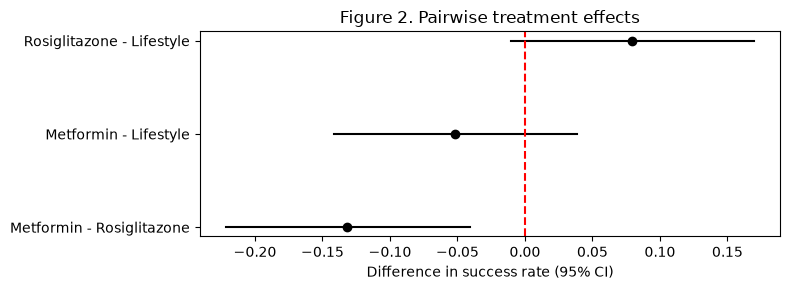

In [ ]:
names = ['Metformin - Rosiglitazone', 'Metformin - Lifestyle', 'Rosiglitazone - Lifestyle']
ates = [ate_met_rosi, ate_met_life, ate_rosi_life]

fig, ax = plt.subplots(figsize=(8, 3))
for i in range(3):
    lo, hi = np.quantile(ates[i], [.025, .975])
    est = np.mean(ates[i])
    ax.plot([lo, hi], [i, i], color='black')
    ax.plot(est, i, 'o', color='black')

ax.axvline(0, color='red', linestyle='--')
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(names)
ax.set_xlabel('Difference in success rate (95% CI)')
ax.set_title('Visualization: Figure 2: Pairwise treatment effects:')
plt.tight_layout()
plt.show()

**Recommendations:** 
Rosiglitazone: The trial provides the strongest evidence of efficacy for Rosiglitazone, which had the highest success rate and significantly outperformed Metformin. However, its advantage over lifestyle adjustment is not statistically significant at the 95% confidence interval level, so the trial does not establish that Rosiglitazone is superior to just a lifestyle intervention.

Metformin: The evidence does not support preferring metformin as an intervention since it had the lowest success rate, was a significantly worseintervention than Rosiglitazone, and showed no observable benefit over lifestyle adjustment.

Lifestyle adjustment: Lifestyle adjustment was statistically indistinguishable from both drugs at the 95% confidence interval level. So, the trial does not provide grounds to recommend a drug intervention over lifestyle adjustment alone.

**Limitations:** These conclusions are derived from a single trial with  ~230 participants per arm, which produces wide confidence intervals. So, differences of up to about 15 percentage points between lifestyle adjustment and either drug cannot be ruled out. The data contain a single binary outcome and no information on treatment side effects, whether people actually correctly adopted the interventions, treatement expense, or how long participants were tracked. Because of this, efficacy alone is not enough to make a decision about whether to adopt and intervention or not. 